# Qdislib — 09 · Scaling up: a bigger molecule and a 25-qubit lattice

Notebook 08 cut **H₂ (4 qubits)**. The real payoff of cutting is running circuits **far too big for your device** — so here we scale up on two fronts:

1. **N₂**, a real molecule — 20 qubits at full size, which we bring to **12 qubits** with an *active space*, and cut into two 6-qubit halves;
2. a **25-qubit spin lattice**, cut into **four blocks with 3 cuts**.

In both cases the energy `⟨H⟩ = Σ_i c_i ⟨P_i⟩` is reconstructed from small subcircuits that **run in parallel under PyCOMPSs**. (We use `software='qiskit'` here for speed at scale; `'cudaq'` / `'qibo'` are one-argument swaps — cutting is backend-agnostic.)

*Cost intuition:* the work is `#Hamiltonian-terms × 6**(#cuts)` subcircuits — it grows with the **number of cuts and terms**, not the circuit's qubit count. That's why a 25-qubit *lattice* (few terms) is cheaper than a 24-qubit *molecule* (~15,000 terms).

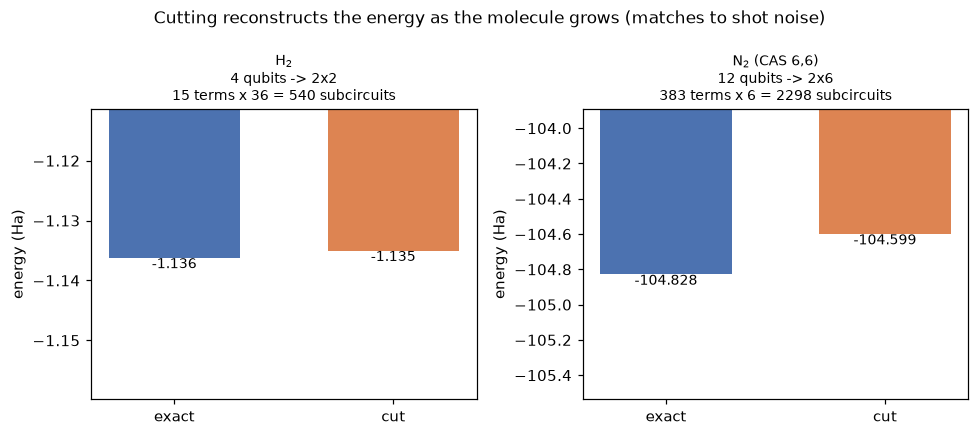

## Start the PyCOMPSs runtime

In [ ]:
import pycompss.interactive as ipycompss
ipycompss.start(graph=True, monitor=1000)

In [ ]:
import os, json
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, SparsePauliOp
import Qdislib as qd


def hardware_efficient(n, seed=1):
    """A generic n-qubit ansatz: RY layer, linear CZ entanglers, RY layer.
    The linear entangler means a single bond crosses each block boundary, so
    find_cut splits it with the fewest possible cuts."""
    rng = np.random.default_rng(seed)
    qc = QuantumCircuit(n)
    for i in range(n):
        qc.ry(float(rng.uniform(0, np.pi)), i)
    for i in range(n - 1):
        qc.cz(i, i + 1)
    for i in range(n):
        qc.ry(0.3, i)
    return qc


def exact_expectation(qc, hamiltonian):
    """Exact <H> of a circuit via statevector (the reference to match)."""
    op = SparsePauliOp.from_list([(p[::-1], c) for c, p in hamiltonian])
    return float(Statevector(qc).expectation_value(op).real)

## 1. A real molecule: N₂ at 12 qubits (active space)

N₂ in the STO-3G basis is **20 qubits** with a Hamiltonian of *thousands* of Pauli terms — too big to reconstruct term-by-term. Chemists tame this with an **active space**: freeze the core orbitals and keep only the chemically active ones. **CAS(6,6)** (6 electrons in 6 orbitals) gives a **12-qubit**, 383-term Hamiltonian — a genuine N₂ calculation, three times H₂'s size. We load a precomputed copy (generation cell below).

In [ ]:
n2 = json.load(open(os.path.join('data', 'n2_cas66_hamiltonian.json')))
HAM_N2 = [(coeff, pauli) for coeff, pauli in n2['terms']]
N_N2 = n2['n_qubits']
print(f"N2 CAS(6,6): {N_N2} qubits, {len(HAM_N2)} Pauli terms | "
      f"FCI reference {n2['fci_energy']:.4f} Ha")

In [ ]:
# How data/n2_cas66_hamiltonian.json was generated (one-off):
#   pip install pyscf openfermion openfermionpyscf
from openfermion import MolecularData, jordan_wigner
from openfermionpyscf import run_pyscf

geometry = [('N', (0, 0, 0)), ('N', (0, 0, 1.10))]
molecule = run_pyscf(MolecularData(geometry, 'sto-3g', 1, 0), run_scf=1, run_fci=1)
# CAS(6,6): freeze the 4 lowest spatial orbitals, keep 6 active -> 12 qubits.
hamiltonian = molecule.get_molecular_hamiltonian(occupied_indices=range(4),
                                                 active_indices=range(4, 10))
qubit_op = jordan_wigner(hamiltonian)   # -> 383 Pauli terms

Build a 12-qubit ansatz and cut it. With a linear entangler only the middle bond crosses, so `find_cut` splits it into **two 6-qubit halves with one cut** (`6**1 = 6` configurations). One energy is then `383 terms × 6 = ~2300` small subcircuits — all independent, so PyCOMPSs runs them in parallel.

In [ ]:
ansatz_n2 = hardware_efficient(N_N2)
cut_n2 = qd.find_cut(ansatz_n2, gate_cut=True, wire_cut=False, max_qubits=N_N2 // 2)
print('N2 cut:', cut_n2, '-> two 6-qubit halves')

energy_n2 = qd.gate_cutting(ansatz_n2, cut_n2, observables=HAM_N2,
                            shots=20_000, software='qiskit')
print(f'N2 <H>  cut-reconstructed: {energy_n2:+.3f} Ha')
print(f'N2 <H>  exact (this ansatz): {exact_expectation(ansatz_n2, HAM_N2):+.3f} Ha')
# The cut value tracks the exact <H> up to ~0.2 Ha: that residual is shot noise
# summed over 383 terms x the quasiprobability overhead -- VQE's measurement cost,
# which more shots, Pauli-term grouping and error mitigation shrink. (The ansatz
# is not optimised; a VQE loop would minimise <H> toward the FCI energy above.)

## 2. A 25-qubit lattice: cut into four blocks with 3 cuts

A **transverse-field Ising** chain `H = -Σ Z_iZ_{i+1} - h Σ X_i` on **25 qubits** — way past any small device. Because it's a lattice, it has only `O(N)` terms (~49), so unlike a molecule we can push the qubit count hard. We cut the 25-qubit ansatz into **four ~6-qubit blocks with 3 cuts** (`6**3 = 216` configurations).

In [ ]:
def ising_hamiltonian(n, h=1.0):
    H = []
    for i in range(n - 1):                      # -Z_i Z_{i+1}
        s = ['I'] * n; s[i] = s[i + 1] = 'Z'; H.append((-1.0, ''.join(s)))
    for i in range(n):                          # -h X_i
        s = ['I'] * n; s[i] = 'X'; H.append((-h, ''.join(s)))
    return H

N_SPIN = 25
HAM_SPIN = ising_hamiltonian(N_SPIN)
ansatz_spin = hardware_efficient(N_SPIN, seed=2)
cut_spin = qd.find_cut(ansatz_spin, gate_cut=True, wire_cut=False, max_qubits=7)
print(f'25-qubit Ising: {len(HAM_SPIN)} terms | {len(cut_spin)} cuts '
      f'-> {len(cut_spin) + 1} blocks: {cut_spin}')

Reconstruct the energy. This is `49 terms × 216 configs ≈ 10⁴` subcircuits (each ≤ 7 qubits) — heavy serially, but embarrassingly parallel under PyCOMPSs. The exact reference is a 25-qubit statevector (~512 MB of RAM; lower `N_SPIN` if that's too much).

In [ ]:
energy_spin = qd.gate_cutting(ansatz_spin, cut_spin, observables=HAM_SPIN,
                              shots=20_000, software='qiskit')
print(f'25-qubit lattice <H>  cut-reconstructed: {energy_spin:+.3f}')
print(f'25-qubit lattice <H>  exact:             {exact_expectation(ansatz_spin, HAM_SPIN):+.3f}')

## Recap

You reconstructed the energy of a **12-qubit N₂** molecule (cut into 2×6) and a **25-qubit lattice** (cut into 4×~6 with 3 cuts) from small subcircuits, in parallel under PyCOMPSs — circuits well beyond a single small device.

The lesson from the two examples: cutting's cost is `#terms × 6**(#cuts)`. A lattice keeps `#terms` small so you can chase **qubit count** (25+); a molecule's `O(N⁴)` terms mean you chase **accuracy** at a modest size (active spaces). The frontier — full N₂ at 20 qubits, or larger molecules — is exactly where cutting, Pauli-term grouping, and distributed execution have to work together.

## Stop the PyCOMPSs runtime

In [ ]:
ipycompss.stop(sync=True)